In [1]:
import numpy as np, pandas as pd
from sklearn.model_selection import GroupKFold, cross_val_predict
from lightgbm import LGBMClassifier

shots = pd.read_pickle("data/shots_features.pkl")
feats2 = ["dist", "angle", "header", "n_def_cone", "gk_dist",
          "under_pressure", "shot_first_time", "shot_one_on_one", "shot_open_goal"]
print(len(shots), "shots loaded")

40864 shots loaded


In [2]:
from sklearn.model_selection import GroupKFold, cross_val_predict
from lightgbm import LGBMClassifier

lg = shots[shots.competition_id.isin([2, 11, 12, 7])].copy()
groups = lg["match_id"] if "match_id" in lg.columns else lg["match_date"].astype(str) + lg["team"].astype(str)

gbm_cv = LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=8, min_child_samples=50,
                        subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1)
lg["xg"] = cross_val_predict(gbm_cv, lg[feats2], lg.goal, groups=groups,
                             cv=GroupKFold(n_splits=5), method="predict_proba")[:, 1]
print("actual goals:", lg.goal.sum(), "| total xG:", round(lg.xg.sum(), 1))

actual goals: 3569 | total xG: 3568.5


In [3]:
players = lg.groupby("player").agg(shots=("goal", "size"), goals=("goal", "sum"), xg=("xg", "sum")).reset_index()
players["raw_ratio"] = players.goals / players.xg
players.sort_values("shots", ascending=False).head()

,player,shots,goals,xg,raw_ratio
337,Cristiano Ronaldo dos Santos Aveiro,219,29,23.937084,1.211509
658,Gonzalo Gerardo Higuaín,179,33,23.086942,1.429379
684,Harry Kane,153,20,18.730669,1.067768
1032,Lionel Andrés Messi Cuccittini,151,23,16.332598,1.408227
1775,Zlatan Ibrahimović,142,31,19.621102,1.579932


In [4]:
from scipy.stats import nbinom
from scipy.optimize import minimize_scalar

def fit_alpha(df):
    f = lambda la: -nbinom.logpmf(df.goals, np.exp(la), np.exp(la) / (np.exp(la) + df.xg)).sum()
    return np.exp(minimize_scalar(f, bounds=(0, np.log(5000)), method="bounded").x)

alpha = fit_alpha(players)
players["skill"] = (alpha + players.goals) / (alpha + players.xg)
players["extra_goals"] = (players.skill - 1) * players.xg
print("alpha:", round(alpha, 1))

alpha: 5000.0


In [5]:
cols = ["player", "shots", "goals", "xg", "raw_ratio", "skill"]
board = players[players.shots >= 30].sort_values("skill", ascending=False)
display(board[cols].head(10).round(2))
display(board[cols].tail(10).round(2))

,player,shots,goals,xg,raw_ratio,skill
1073,Luis Alberto Suárez Díaz,134,37,24.92,1.48,1.0
1775,Zlatan Ibrahimović,142,31,19.62,1.58,1.0
658,Gonzalo Gerardo Higuaín,179,33,23.09,1.43,1.0
608,Gareth Frank Bale,81,19,9.41,2.02,1.0
1032,Lionel Andrés Messi Cuccittini,151,23,16.33,1.41,1.0
1567,Sergio Leonel Agüero del Castillo,113,20,13.43,1.49,1.0
156,Antoine Griezmann,90,21,14.54,1.44,1.0
965,Karim Benzema,98,24,18.10,1.33,1.0
686,Hatem Ben Arfa,87,12,6.23,1.93,1.0
1593,Sofiane Boufal,51,9,3.64,2.47,1.0


,player,shots,goals,xg,raw_ratio,skill
1576,Shinji Okazaki,44,5,8.45,0.59,1.0
268,Carlos Alberto Vela Garrido,61,5,8.70,0.58,1.0
1304,Nicolas de Roussel de Préville,91,6,10.06,0.60,1.0
66,Aleksandar Mitrović,78,7,11.17,0.63,1.0
1785,Álvaro Vázquez García,47,4,8.71,0.46,1.0
1057,Luca Toni,58,3,7.74,0.39,1.0
1149,Martin Braithwaite Christensen,105,9,13.79,0.65,1.0
262,Cameron Jerome,49,3,8.56,0.35,1.0
635,Giampaolo Pazzini,76,3,8.91,0.34,1.0
463,Edin Džeko,86,6,12.21,0.49,1.0


In [6]:
early = lg[lg.match_date < "2016-03-01"].groupby("player").agg(goals=("goal", "sum"), xg=("xg", "sum"), n1=("goal", "size"))
late  = lg[lg.match_date >= "2016-03-01"].groupby("player").agg(g2=("goal", "sum"), x2=("xg", "sum"), n2=("goal", "size"))
a1 = fit_alpha(early)

d = early.join(late, how="inner")
d = d[(d.n1 >= 15) & (d.n2 >= 15)]

preds = {"xG only (everyone average)": d.x2,
         "raw goals/xG": d.x2 * d.goals / d.xg,
         "shrunk skill": d.x2 * (a1 + d.goals) / (a1 + d.xg)}
print(len(d), "players")
for name, p_ in preds.items():
    print(f"{name:28s} error: {((d.g2 - p_) ** 2).mean():.3f}")

204 players
xG only (everyone average)   error: 2.565
raw goals/xG                 error: 3.559
shrunk skill                 error: 2.563


In [7]:
def fit_alpha(df, hi=1e7):
    f = lambda la: -nbinom.logpmf(df.goals, np.exp(la), np.exp(la) / (np.exp(la) + df.xg)).sum()
    return np.exp(minimize_scalar(f, bounds=(0, np.log(hi)), method="bounded").x)

print("alpha (wide):", round(fit_alpha(players)))

alpha (wide): 7053591


In [8]:
d["early_resid"] = (d.goals - d.xg) / d.n1
d["late_resid"] = (d.g2 - d.x2) / d.n2
print(d[["early_resid", "late_resid"]].corr().round(3))

             early_resid  late_resid
early_resid        1.000       0.051
late_resid         0.051       1.000


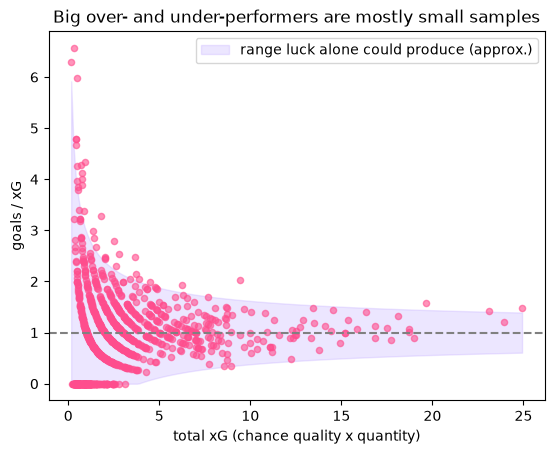

In [9]:
import os
import matplotlib.pyplot as plt
os.makedirs("images", exist_ok=True)

pl = players[players.shots >= 10]
xs = np.linspace(pl.xg.min(), pl.xg.max(), 200)
plt.fill_between(xs, np.clip(1 - 1.96/np.sqrt(xs), 0, None), 1 + 1.96/np.sqrt(xs),
                 color="#B79CFF", alpha=0.25, label="range luck alone could produce (approx.)")
plt.scatter(pl.xg, pl.raw_ratio, color="#FF4D8D", alpha=0.6, s=20)
plt.axhline(1, color="gray", ls="--")
plt.xlabel("total xG (chance quality x quantity)"); plt.ylabel("goals / xG")
plt.title("Big over- and under-performers are mostly small samples")
plt.legend()
plt.savefig("images/finishing_funnel.png", dpi=150, bbox_inches="tight")
plt.show()

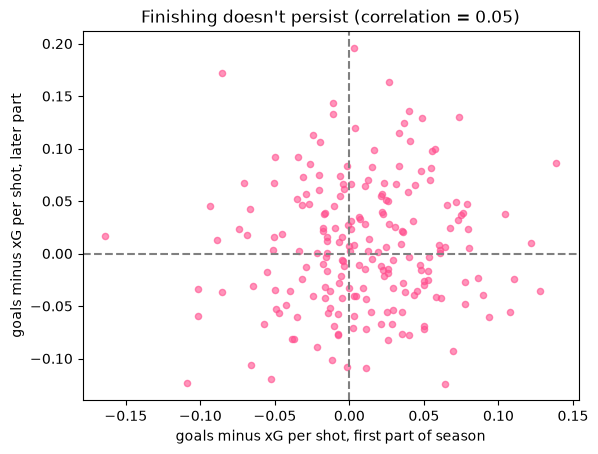

In [10]:
plt.scatter(d.early_resid, d.late_resid, color="#FF4D8D", alpha=0.6, s=20)
plt.axhline(0, color="gray", ls="--"); plt.axvline(0, color="gray", ls="--")
plt.xlabel("goals minus xG per shot, first part of season")
plt.ylabel("goals minus xG per shot, later part")
plt.title(f"Finishing doesn't persist (correlation = {d.early_resid.corr(d.late_resid):.2f})")
plt.savefig("images/finishing_persistence.png", dpi=150, bbox_inches="tight")
plt.show()